In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

root = Path.cwd()
if not (root / "data").exists():
    root = root.parent

train_df = pd.read_csv(root / "data/processed/train_split.csv")
train_features = pd.read_csv(root / "data/processed/train_features.csv")
val_features = pd.read_csv(root / "data/processed/val_features.csv")

print("Training samples:", len(train_features))
print("Validation samples:", len(val_features))


Training samples: 14241
Validation samples: 3490


In [2]:

# Calculate typical engine lifespan using ONLY training engines
engine_lifespans = train_df.groupby("engine_id")["cycle"].max()

typical_lifespan = engine_lifespans.median()

print("Typical engine lifespan:", typical_lifespan, "cycles")

# Predict remaining life using engine age only
y_true = val_features["RUL"]

y_pred = np.maximum(
    0,
    typical_lifespan - val_features["cycle"]
)

# Evaluate
mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

# How often does the model overestimate RUL?
overestimation = np.mean(y_pred > y_true) * 100

print("\n=== BASELINE RESULTS ===")
print(f"MAE: {mae:.2f} cycles")
print(f"RMSE: {rmse:.2f} cycles")
print(f"Overestimation: {overestimation:.2f}%")

# Show example predictions
results = val_features[["engine_id", "cycle", "RUL"]].copy()
results["predicted_RUL"] = y_pred
results["absolute_error"] = abs(
    results["RUL"] - results["predicted_RUL"]
)

display(results.sample(10, random_state=42))


Typical engine lifespan: 199.0 cycles

=== BASELINE RESULTS ===
MAE: 34.98 cycles
RMSE: 40.54 cycles
Overestimation: 44.38%


,engine_id,cycle,RUL,predicted_RUL,absolute_error
295,5,162,107,37.0,70.0
3155,84,39,228,160.0,68.0
3375,84,259,8,0.0,8.0
1462,34,109,86,90.0,4.0
969,23,122,46,77.0,31.0
2111,54,77,180,122.0,58.0
2725,77,147,7,52.0,45.0
144,1,174,18,25.0,7.0
1587,40,68,120,131.0,11.0
2304,71,42,166,157.0,9.0


In [3]:

from xgboost import XGBRegressor

# Select model input features
# Engine ID is an identifier, not a predictive feature.
# RUL is our target and must never be an input.

feature_cols = [
    col for col in train_features.columns
    if col not in ["engine_id", "RUL"]
]

X_train = train_features[feature_cols]
y_train = train_features["RUL"]

X_val = val_features[feature_cols]
y_val = val_features["RUL"]

print("Number of input features:", len(feature_cols))
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))

# Initialize XGBoost
model = XGBRegressor(
    n_estimators=400,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

# Train the model
model.fit(X_train, y_train)

print("\nXGBoost training complete!")


Number of input features: 61
Training samples: 14241
Validation samples: 3490

XGBoost training complete!


In [4]:

# Predict remaining useful life
xgb_pred = model.predict(X_val)

# RUL cannot be negative
xgb_pred = np.maximum(0, xgb_pred)

# Calculate metrics
xgb_mae = mean_absolute_error(y_val, xgb_pred)
xgb_rmse = np.sqrt(mean_squared_error(y_val, xgb_pred))
xgb_over = np.mean(xgb_pred > y_val) * 100

print("=== XGBOOST RESULTS ===")
print(f"MAE: {xgb_mae:.2f} cycles")
print(f"RMSE: {xgb_rmse:.2f} cycles")
print(f"Overestimation: {xgb_over:.2f}%")

print("\n=== BASELINE VS XGBOOST ===")
comparison = pd.DataFrame({
    "Model": ["Age Baseline", "XGBoost"],
    "MAE": [mae, xgb_mae],
    "RMSE": [rmse, xgb_rmse],
    "Overestimation %": [overestimation, xgb_over]
})

display(comparison.round(2))

# Inspect example predictions
predictions = val_features[
    ["engine_id", "cycle", "RUL"]
].copy()

predictions["predicted_RUL"] = xgb_pred
predictions["absolute_error"] = abs(
    predictions["RUL"] - predictions["predicted_RUL"]
)

print("\n=== SAMPLE PREDICTIONS ===")
display(predictions.sample(10, random_state=42).round(2))


=== XGBOOST RESULTS ===
MAE: 21.78 cycles
RMSE: 30.19 cycles
Overestimation: 55.27%

=== BASELINE VS XGBOOST ===


,Model,MAE,RMSE,Overestimation %
0,Age Baseline,34.98,40.54,44.38
1,XGBoost,21.78,30.19,55.27



=== SAMPLE PREDICTIONS ===


,engine_id,cycle,RUL,predicted_RUL,absolute_error
295,5,162,107,114.620003,7.62
3155,84,39,228,167.839996,60.16
3375,84,259,8,13.830000,5.83
1462,34,109,86,75.790001,10.21
969,23,122,46,44.290001,1.71
2111,54,77,180,132.279999,47.72
2725,77,147,7,15.750000,8.75
144,1,174,18,16.620001,1.38
1587,40,68,120,131.949997,11.95
2304,71,42,166,144.089996,21.91


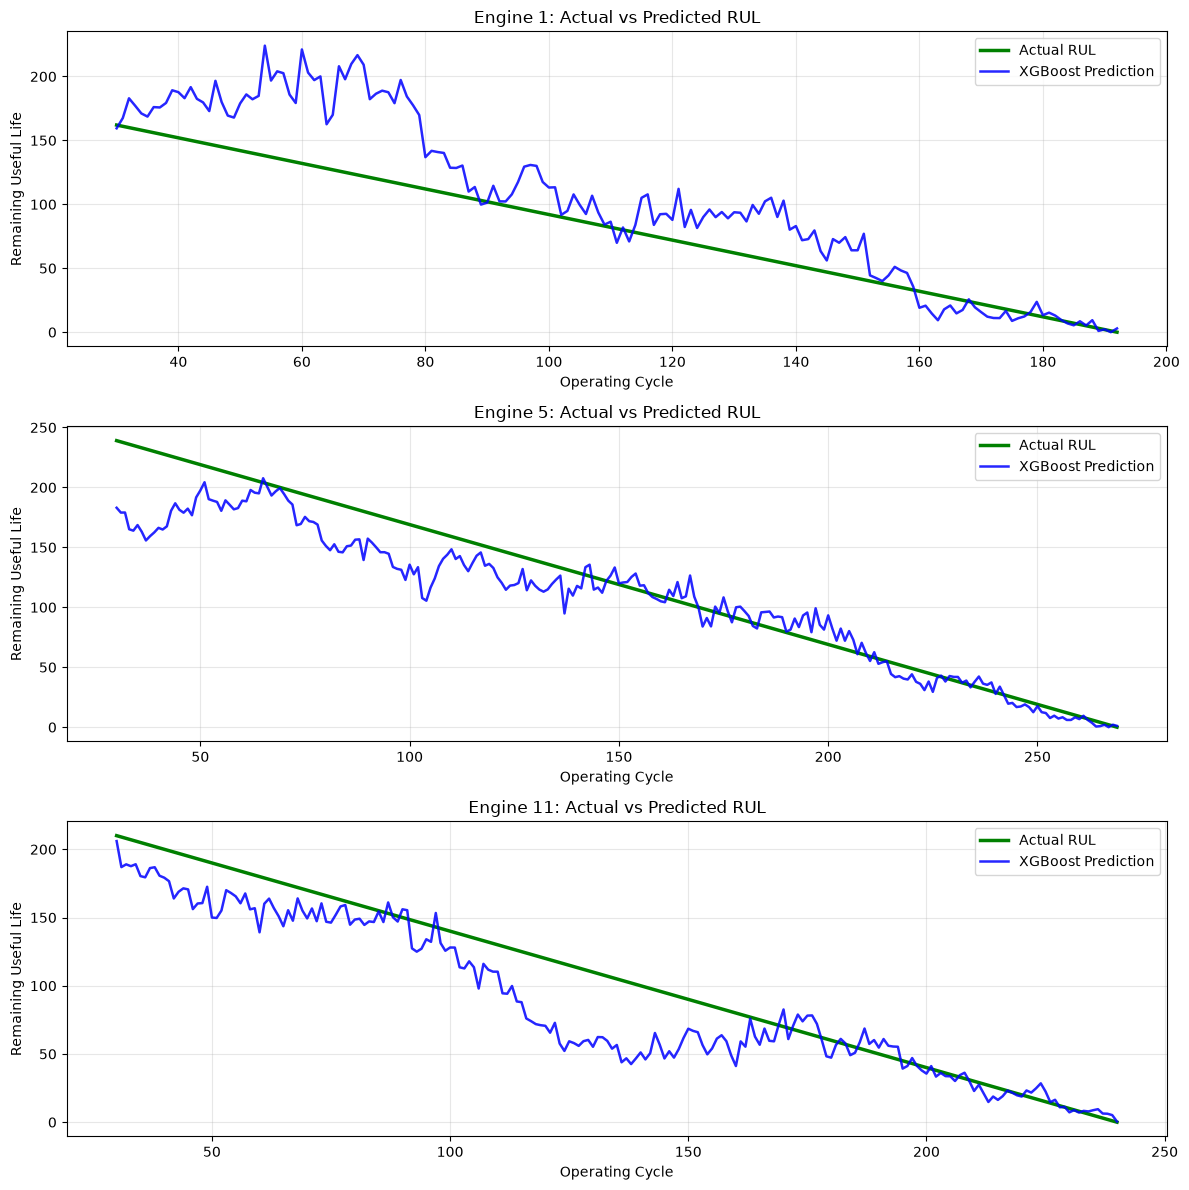

In [5]:

import matplotlib.pyplot as plt

# Select 3 unseen validation engines
engine_ids = sorted(predictions["engine_id"].unique())[:3]

fig, axes = plt.subplots(3, 1, figsize=(12, 12))

for ax, engine_id in zip(axes, engine_ids):
    engine = predictions[
        predictions["engine_id"] == engine_id
    ].sort_values("cycle")

    ax.plot(
        engine["cycle"],
        engine["RUL"],
        label="Actual RUL",
        color="green",
        linewidth=2.5
    )

    ax.plot(
        engine["cycle"],
        engine["predicted_RUL"],
        label="XGBoost Prediction",
        color="blue",
        linewidth=1.8,
        alpha=0.85
    )

    ax.set_title(f"Engine {engine_id}: Actual vs Predicted RUL")
    ax.set_xlabel("Operating Cycle")
    ax.set_ylabel("Remaining Useful Life")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [6]:

# Evaluate engines when they have <=30 cycles remaining
near_failure = predictions[predictions["RUL"] <= 30].copy()

near_mae = mean_absolute_error(
    near_failure["RUL"],
    near_failure["predicted_RUL"]
)

# How much the model overestimates when it is wrong
errors = near_failure["predicted_RUL"] - near_failure["RUL"]
overestimated = errors[errors > 0]

print("=== NEAR-FAILURE PERFORMANCE ===")
print("Samples:", len(near_failure))
print(f"MAE: {near_mae:.2f} cycles")
print(f"Overestimation frequency: {(errors > 0).mean()*100:.2f}%")
print(f"Mean overestimation magnitude: {overestimated.mean():.2f} cycles")
print(f"Overestimates by 20+ cycles: {(errors >= 20).sum()}")


=== NEAR-FAILURE PERFORMANCE ===
Samples: 620
MAE: 5.10 cycles
Overestimation frequency: 66.61%
Mean overestimation magnitude: 5.55 cycles
Overestimates by 20+ cycles: 5


In [7]:

# Analyze predictions close to engine failure
near = predictions[predictions["RUL"] <= 30].copy()

# Positive error means overestimating remaining life
near["error"] = near["predicted_RUL"] - near["RUL"]

# Show the 10 most dangerous overestimates
worst = near.sort_values("error", ascending=False).head(10)

print("=== TOP 10 RUL OVERESTIMATES ===")
display(
    worst[
        ["engine_id", "cycle", "RUL", "predicted_RUL", "error"]
    ].round(2)
)

# Identify engines with large prediction errors
dangerous = near[near["error"] >= 20]

print("\n=== LARGE OVERESTIMATES ===")
print("Number of predictions:", len(dangerous))
print("Affected engines:", dangerous["engine_id"].unique())
print("Largest overestimate:", round(near["error"].max(), 2))


=== TOP 10 RUL OVERESTIMATES ===


,engine_id,cycle,RUL,predicted_RUL,error
1807,45,129,29,66.610001,37.61
1806,45,128,30,57.880001,27.88
1810,45,132,26,49.939999,23.94
2033,46,226,30,50.380001,20.38
719,13,135,28,48.020000,20.02
722,13,138,25,44.439999,19.44
2036,46,229,27,46.200001,19.20
1815,45,137,21,40.180000,19.18
721,13,137,26,42.740002,16.74
723,13,139,24,40.570000,16.57



=== LARGE OVERESTIMATES ===
Number of predictions: 5
Affected engines: [13 45 46]
Largest overestimate: 37.61


In [8]:

# Compare different prediction safety buffers

actual = predictions["RUL"].to_numpy()
predicted = predictions["predicted_RUL"].to_numpy()

near_mask = actual <= 30

results = []

for buffer in [0, 5, 10, 15]:

    adjusted = np.maximum(0, predicted - buffer)

    near_actual = actual[near_mask]
    near_pred = adjusted[near_mask]

    errors = near_pred - near_actual

    results.append({
        "Buffer": buffer,
        "Overall MAE": mean_absolute_error(actual, adjusted),
        "Overall RMSE": np.sqrt(
            mean_squared_error(actual, adjusted)
        ),
        "Near Failure MAE": mean_absolute_error(
            near_actual, near_pred
        ),
        "Near Overestimation %": (errors > 0).mean() * 100,
        "Large Overestimates (20+)": (errors >= 20).sum(),
        "Worst Overestimate": max(0, errors.max())
    })

buffer_comparison = pd.DataFrame(results)

print("=== SAFETY BUFFER EXPERIMENT ===")
display(buffer_comparison.round(2))


=== SAFETY BUFFER EXPERIMENT ===


,Buffer,Overall MAE,Overall RMSE,Near Failure MAE,Near Overestimation %,Large Overestimates (20+),Worst Overestimate
0,0,21.78,30.19,5.10,66.61,5,37.61
1,5,21.89,30.22,5.17,30.81,2,32.61
2,10,23.03,31.02,7.33,11.29,1,27.61
3,15,24.71,32.50,9.75,3.39,1,22.61


=== TOP 15 MOST IMPORTANT FEATURES ===


,Importance
sensor_11_latest,0.162469
sensor_17_mean30,0.118506
sensor_4_latest,0.104178
sensor_3_mean30,0.077856
cycle,0.061815
sensor_7_latest,0.041374
sensor_12_latest,0.040940
sensor_15_latest,0.028849
sensor_2_mean30,0.020353
sensor_20_mean30,0.018270


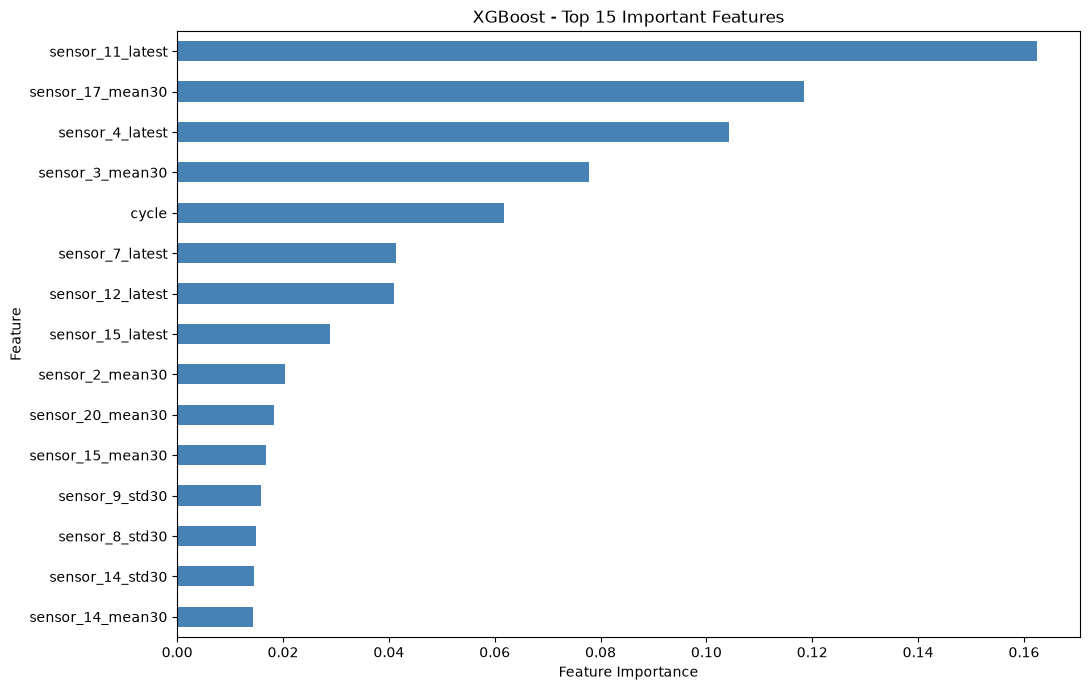


Cycle importance: 0.0618


In [9]:

import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance from trained XGBoost model
importance = pd.Series(
    model.feature_importances_,
    index=feature_cols
).sort_values(ascending=False)

print("=== TOP 15 MOST IMPORTANT FEATURES ===")
display(importance.head(15).to_frame("Importance"))

# Plot feature importance
plt.figure(figsize=(11, 7))

importance.head(15).sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("XGBoost - Top 15 Important Features")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print("\nCycle importance:", round(importance["cycle"], 4))


In [10]:

import json

model_dir = root / "models"
model_dir.mkdir(parents=True, exist_ok=True)

# Save trained XGBoost model
model.save_model(str(model_dir / "xgboost_fd001.json"))

# Save exact feature names and order
with open(model_dir / "xgboost_features.json", "w") as f:
    json.dump(feature_cols, f, indent=2)

print("XGBoost model and feature configuration saved!")


XGBoost model and feature configuration saved!
